# Sales & Demand Planning
**Student notebook**

A planner reviews weekly sales for two products, tests a simple forecast and considers a stock action. Use the displayed evidence to explain each result. This is supplied teaching data; no claim of real-company provenance is made.

Run setup and Baseline first. For each task, run the starting setting, change only the marked parameter, and interpret the output. Later tasks use fixed references and reset their stock settings independently.

## Your planning decision

You act as the planner for two products in a teaching scenario. One row describes one SKU in one Sunday-labelled calendar week. Compare the sales forecasts for both products, then explore an illustrative order for SKU_A for the week labelled **29 December 2024**. Company identity and actual stock policy are not supplied.

**Before starting:** run the setup cells in order, then run the baseline. Complete Tasks 1–5 in order. For Tasks 4 and 5, use the fixed latest-three-week forecast. Task 4 starts at inventory position 180 and buffer factor 1.0. Task 5 resets inventory position to 180 before changing the buffer factor.

**Forecast timing:** the final 20 calendar weeks, 11 August–22 December 2024, form the evaluation period. Forecast one week using earlier sales, observe the actual, then move forward. Earlier evaluation actuals can inform later one-week forecasts. The buffer uses sales variation from before the evaluation period.

**Business meaning:** the simple forecasts use past sales, without next week’s promotion plan. Review planned promotions separately. Sales alone cannot reveal unmet demand because stockout and unfilled-request records are absent. Treat the stock rule as an illustrative policy, not an optimal order or a service guarantee.


## Dataset and assumptions
One row should represent one SKU in one week, labelled by a Sunday date. `Sales_Units` is recorded sales in units/week; it is not unconstrained demand without availability information. `Is_Promo`: 1 = recorded promotion, 0 = nonpromotion; missing = unknown. `Price` is the recorded unit price; its currency and exact price basis are not supplied, so no revenue or profit is calculated.

The raw snapshot has 206 rows over 2023-01-01 to 2024-12-22, plus an invalid date. The reviewed calendar has 104 weeks per SKU. It retains unknown sales and does not cap recorded promotions or fill prices. A Sunday label alone does not prove the business week-ending convention.

**Preparation policy:** assume the three exact repeated exports are duplicates; quarantine the invalid date and both conflicting SKU/week records. Negative sales become unknown pending confirmation of returns versus errors. Preserve all raw/quarantined evidence. This is a conservative teaching policy, not a verified operational correction.

The raw CSV is supplied alongside the notebook and embedded as the same versioned snapshot, so Colab needs no upload or external download. If an adjacent CSV differs, the loader stops for version review.

## Provided setup
Run the following cells once. You do not need to edit or study every helper function. The five experiment cells are below **Baseline**.

In [1]:
import io
import base64
import hashlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display


RAW_SHA256 = 'e044f37853df000d9760dac449ed94edc219bfd8b0ac7ba60344d9038b377c57'
RAW_SNAPSHOT = 'V2VlayxTS1UsU2FsZXNfVW5pdHMsSXNfUHJvbW8sUHJpY2UKMjAyMy0wNS0xNCxTS1VfQiwyMTMsMCwxOS40OQoyMDIzLTAzLTE5LFNLVV9BLDE1NywwLDE0Ljk5CjIwMjQtMDktMjksU0tVX0IsLTI1LDEsMTQuNDg5OTk5OTk5OTk5OTk4CjIwMjQtMDEtMjEsU0tVX0IsMTk3LDAsMTkuNDkKMjAyMy0xMS0xOSxTS1VfQiwxODcsMCwxOS40OQoyMDI0LTA1LTI2LFNLVV9BLDE4MiwwLDE0Ljk5CjIwMjQtMTEtMTAsU0tVX0EsMTQ3LDAsMTQuOTkKMjAyMy0wNS0xNCxTS1VfQSwxNDUsMCwxNC45OQoyMDIzLTAxLTI5LFNLVV9BLDE0OCwwLDE0Ljk5CjIwMjMtMDItMTIsU0tVX0EsMTcwLDAsMTQuOTkKMjAyNC0xMS0yNCxTS1VfQSwxNDYsMCwxNC45OQoyMDI0LTAyLTA0LFNLVV9BLDIyNSwxLDkuOTkKMjAyMy0wNy0zMCxTS1VfQSwxMzEsMCwxNC45OQoyMDI0LTAxLTE0LFNLVV9CLDE5NiwwLDE5LjQ5CjIwMjMtMDUtMjEsU0tVX0IsMjI3LDAsMTkuNDkKMjAyMy0xMC0wMSxTS1VfQSwxMzAsMCwxNC45OQoyMDI0LTA5LTE1LFNLVV9BLDE0NCwwLDE0Ljk5CjIwMjQtMTItMDEsU0tVX0EsMTM3LDAsMTQuOTkKMjAyNC0wMy0xMCxTS1VfQiwyMzAsMCwxOS40OQoyMDIzLTA0LTAyLFNLVV9BLDE0MywwLDE0Ljk5CjIwMjMtMDMtMjYsU0tVX0EsMTY1LDAsMTQuOTkKMjAyNC0xMC0yNyxTS1VfQSwxMjcsMCwxNC45OQoyMDIzLTAyLTEyLFNLVV9CLDE3OSwwLDE5LjQ5CjIwMjQtMDItMTgsU0tVX0IsMjEzLDAsMTkuNDkKMjAyNC0wNy0xNCxTS1VfQiwyMTYsMCwxOS40OQoyMDIzLTA5LTAzLFNLVV9CLDE4MywwLDE5LjQ5CjIwMjQtMDgtMjUsU0tVX0EsMTUwLDAsMTQuOTkKMjAyNC0wMy0xNyxTS1VfQSwxNjAsMCwxNC45OQoyMDIzLTAzLTA1LFNLVV9CLDIyMiwwLDE5LjQ5CjIwMjQtMDMtMjQsU0tVX0IsMzE2LDEsMTQuNDg5OTk5OTk5OTk5OTk4CjIwMjQtMDEtMTQsU0tVX0EsLTUsMCwxNC45OQoyMDI0LTA4LTE4LFNLVV9BLDEzNywwLDE0Ljk5CjIwMjMtMDYtMTgsU0tVX0IsMjA3LDAsMTkuNDkKMjAyMy0wNC0yMyxTS1VfQiwtNSwwLDE5LjQ5CjIwMjMtMDUtMDcsU0tVX0EsMTUxLDAsMTQuOTkKMjAyMy0wNC0wMixTS1VfQSwxNDMsMCwxNC45OQoyMDIzLTAxLTAxLFNLVV9BLDE0NSwwLDE0Ljk5CjIwMjMtMDQtMTYsU0tVX0IsMjk3LDEsMTQuNDg5OTk5OTk5OTk5OTk4CjIwMjMtMDEtMTUsU0tVX0IsMjcyLDEsMTQuNDg5OTk5OTk5OTk5OTk4CjIwMjMtMDQtMDIsU0tVX0IsMjA2LDAsMTkuNDkKMjAyNC0wMS0xNCxTS1VfQSwxNjYsMCwxNC45OQoyMDIzLTAxLTE1LFNLVV9BLDIxMCwxLDkuOTkKMjAyMy0wMS0wOCxTS1VfQiwxOTYsMCwxOS40OQoyMDI0LTAxLTA3LFNLVV9BLDE1OSwwLDE0Ljk5CjIwMjQtMDQtMDcsU0tVX0EsMTcyLDAsMTQuOTkKMjAyMy0wNC0yMyxTS1VfQSwxNTIsMCwxNC45OQoyMDI0LTA5LTI5LFNLVV9BLDIwMywxLDkuOTkKMjAyNC0xMS0xNyxTS1VfQSwyMDUsMSw5Ljk5CjIwMjMtMTItMTcsU0tVX0EsMjA3LDEsOS45OQoyMDI0LTA1LTI2LFNLVV9CLDIyNSwwLDE5LjQ5CjIwMjMtMTAtMDgsU0tVX0IsMTc5LDAsMTkuNDkKMjAyNC0wMS0yMSxTS1VfQSwxNjcsMCwxNC45OQoyMDI0LTAzLTAzLFNLVV9BLDE2OCwwLDE0Ljk5CjIwMjQtMDktMDEsU0tVX0IsMTkzLDAsMTkuNDkKMjAyMy0wOS0xMCxTS1VfQSwxODIsMSw5Ljk5CjIwMjMtMDctMjMsU0tVX0IsMjM5LDEsMTQuNDg5OTk5OTk5OTk5OTk4CjIwMjQtMTItMDEsU0tVX0EsMTM3LDAsMTQuOTkKMjAyNC0wOS0wOCxTS1VfQiwyMTAsMCwxOS40OQoyMDIzLTA0LTA5LFNLVV9CLDIxNiwwLDE5LjQ5CjIwMjMtMDItMDUsU0tVX0EsMTUwLDAsMTQuOTkKMjAyNC0wNC0wNyxTS1VfQiwyNDYsMCwxOS40OQoyMDI0LTA2LTA5LFNLVV9CLDE5OSwwLDE5LjQ5CjIwMjQtMTAtMDYsU0tVX0EsMTMyLDAsMTQuOTkKMjAyNC0xMC0yMCxTS1VfQiwxNzcsMCwxOS40OQoyMDIzLTEyLTMxLFNLVV9BLDE0NCwwLDE0Ljk5CjIwMjQtMDYtMDIsU0tVX0EsMTM4LDAsMTQuOTkKMjAyMy0wNy0wOSxTS1VfQSwxNDcsMCwxNC45OQoyMDIzLTExLTI2LFNLVV9CLDE4OSwwLDE5LjQ5CjIwMjMtMDMtMTIsU0tVX0IsMjA5LDAsMTkuNDkKMjAyMy0wOS0yNCxTS1VfQSwxMTQsMCwxNC45OQoyMDI0LTA4LTA0LFNLVV9BLDE0MCwwLDE0Ljk5CjIwMjMtMTItMTAsU0tVX0EsMTI1LDAsMTQuOTkKMjAyMy0wOS0yNCxTS1VfQiwxNzgsMCwxOS40OQoyMDIzLTA2LTExLFNLVV9BLDEzNywwLDE0Ljk5CjIwMjQtMTAtMjAsU0tVX0EsMTM2LDAsMTQuOTkKMjAyMy0wOC0xMyxTS1VfQSwxMzMsMCwxNC45OQoyMDI0LTAzLTMxLFNLVV9CLDIwNCwwLDE5LjQ5CjIwMjQtMDktMjIsU0tVX0EsMTM5LDAsMTQuOTkKMjAyMy0xMS0xOSxTS1VfQSwxMzEsMCwxNC45OQoyMDI0LTExLTAzLFNLVV9BLDE0NiwwLDE0Ljk5CjIwMjQtMDYtMDIsU0tVX0IsMjI3LDAsMTkuNDkKMjAyMy0xMC0wOCxTS1VfQSwxMzYsMCwxNC45OQoyMDIzLTA3LTAyLFNLVV9CLDE5MCwwLDE5LjQ5CjIwMjMtMDgtMTMsU0tVX0IsMTc1LDAsMTkuNDkKMjAyNC0xMi0wOCxTS1VfQSwxNDksMCwxNC45OQoyMDIzLTAyLTE5LFNLVV9BLDE2NCwwLDE0Ljk5CjIwMjMtMDQtMzAsU0tVX0EsMTY0LDAsMTQuOTkKMjAyNC0xMS0xNyxTS1VfQiwxODgsMCwxOS40OQoyMDIzLTExLTEyLFNLVV9BLDEyNywwLDE0Ljk5CjIwMjMtMDgtMjcsU0tVX0IsMTk5LDAsMTkuNDkKMjAyNC0wOC0wNCxTS1VfQiwxOTMsMCwxOS40OQoyMDIzLTAyLTA1LFNLVV9CLDIxMywwLDE5LjQ5CjIwMjMtMTEtMjYsU0tVX0EsMTQ5LDAsMTQuOTkKMjAyNC0wMS0yOCxTS1VfQSwxNTIsMCwxNC45OQoyMDIzLTA1LTA3LFNLVV9CLDIwNiwwLDE5LjQ5CjIwMjQtMTItMTUsU0tVX0EsMTUyLDAsMTQuOTkKMjAyNC0xMC0xMyxTS1VfQSwxMzYsMCwxNC45OQoyMDIzLTA5LTAzLFNLVV9BLDExNywwLDE0Ljk5CjIwMjQtMDUtMTIsU0tVX0EsMjUyLDEsOS45OQoyMDI0LTAzLTE3LFNLVV9CLDIzMiwwLDE5LjQ5CjIwMjQtMDQtMTQsU0tVX0IsMjI0LDAsMTkuNDkKMjAyMy0xMC0yMixTS1VfQiwxNzgsMCwxOS40OQoyMDI0LTA2LTE2LFNLVV9CLDIxOCwwLDE5LjQ5CjIwMjMtMDEtMDEsU0tVX0IsMTg5LDAsMTkuNDkKMjAyMy0wNS0yMSxTS1VfQSwxNzIsMCwxNC45OQoyMDI0LTAyLTI1LFNLVV9BLDE2NCwwLDE0Ljk5CjIwMjQtMDYtMTYsU0tVX0EsMTYxLDAsMTQuOTkKMjAyNC0wOS0xNSxTS1VfQiwyMDQsMCwxOS40OQoyMDI0LTAzLTEwLFNLVV9BLDE2MCwwLDE0Ljk5CjIwMjMtMTEtMDUsU0tVX0IsMTkyLDAsMTkuNDkKMjAyNC0wNS0wNSxTS1VfQiwyMjAsMCwxOS40OQoyMDIzLTEwLTE1LFNLVV9CLDE4NCwwLDE5LjQ5CjIwMjMtMTAtMDEsU0tVX0IsMTgyLDAsMTkuNDkKMjAyMy0wMS0yMixTS1VfQSwxNjMsMCwxNC45OQoyMDIzLTA2LTA0LFNLVV9BLDE1NCwwLDE0Ljk5CjIwMjMtMDQtMDksU0tVX0EsMTQ1LDAsMTQuOTkKMjAyMy0wMy0xOSxTS1VfQiwyMDUsMCwxOS40OQoyMDIzLTA3LTIzLFNLVV9BLDEzNiwwLDE0Ljk5CjIwMjMtMTItMzEsU0tVX0IsMTgyLDAsMTkuNDkKMjAyNC0xMi0xNSxTS1VfQiwyMTAsMCwxOS40OQoyMDI0LTA2LTMwLFNLVV9BLDE1NywwLDE0Ljk5CjIwMjMtMDUtMjgsU0tVX0EsMjE2LDEsOS45OQoyMDI0LTExLTI0LFNLVV9CLDI2OCwxLDE0LjQ4OTk5OTk5OTk5OTk5OAoyMDI0LTA1LTE5LFNLVV9CLDMwMywxLDE0LjQ4OTk5OTk5OTk5OTk5OAoyMDIzLTEyLTEwLFNLVV9CLDI2OCwxLDE0LjQ4OTk5OTk5OTk5OTk5OAoyMDI0LTAxLTI4LFNLVV9CLDI2NiwxLDE0LjQ4OTk5OTk5OTk5OTk5OAoyMDI0LTA0LTE0LFNLVV9BLDE4MywwLDE0Ljk5CjIwMjQtMDYtMDksU0tVX0EsMTcwLDAsMTQuOTkKMjAyNC0xMC0yNyxTS1VfQiwxNzUsMCwxOS40OQoyMDI0LTAyLTExLFNLVV9CLDIxNSwwLDE5LjQ5CjIwMjMtMTAtMjksU0tVX0IsMTI3NSwxLDE0LjQ4OTk5OTk5OTk5OTk5OAoyMDI0LTEyLTIyLFNLVV9BLDE1MCwwLDE0Ljk5CjIwMjQtMDQtMjEsU0tVX0IsMjI4LDAsMTkuNDkKMjAyMy0wMy0wNSxTS1VfQSwyMjksMSw5Ljk5CjIwMjMtMTItMTcsU0tVX0IsMjAyLDAsMTkuNDkKMjAyNC0wMi0wNCxTS1VfQiwyMDUsMCwxOS40OQoyMDI0LTA4LTExLFNLVV9CLDI3NCwxLDE0LjQ4OTk5OTk5OTk5OTk5OAoyMDIzLTEyLTAzLFNLVV9BLDE0NCwwLDE0Ljk5CjIwMjQtMDctMjEsU0tVX0IsMjAzLDAsMTkuNDkKMjAyNC0wOS0yMixTS1VfQiwxNzksMCwxOS40OQoyMDI0LTA3LTA3LFNLVV9CLDE4OCwwLDE5LjQ5CjIwMjMtMDgtMjAsU0tVX0EsMTIxLDAsMTQuOTkKMjAyNC0xMS0xMCxTS1VfQiwyMDgsMCwxOS40OQoyMDIzLTA5LTE3LFNLVV9BLDEwOCwwLDE0Ljk5CjIwMjMtMDgtMjAsU0tVX0IsMTg4LDAsMTkuNDkKMjAyMy0xMC0yOSxTS1VfQSwxMjgsMCwxNC45OQoyMDIzLTA2LTE4LFNLVV9BLDE0NCwwLDE0Ljk5CjIwMjMtMDEtMjIsU0tVX0IsMTk1LDAsMTkuNDkKMjAyMy0wNS0yOCxTS1VfQiwyMDYsMCwxOS40OQoyMDIzLTEwLTIyLFNLVV9BLDE4MCwxLDkuOTkKMjAyMy0xMi0wMyxTS1VfQiwyMDAsMCwxOS40OQoyMDI0LTA4LTExLFNLVV9BLDE5MywxLDkuOTkKMjAyMy0wNy0wOSxTS1VfQiwyMDQsMCwxOS40OQoyMDIzLTA5LTE3LFNLVV9CLDI0NCwxLDE0LjQ4OTk5OTk5OTk5OTk5OAoyMDI0LTA0LTI4LFNLVV9CLDIwNywwLDE5LjQ5CjIwMjQtMDQtMjgsU0tVX0EsMTY1LDAsMTQuOTkKMjAyMy0wMy0xMixTS1VfQSwxNTYsMCwxNC45OQoyMDI0LTA2LTMwLFNLVV9CLDIwNiwwLDE5LjQ5CjIwMjQtMDUtMTksU0tVX0EsMTY3LDAsMTQuOTkKMjAyMy0xMC0xNSxTS1VfQSwxMzAsMCwxNC45OQoyMDIzLTA0LTMwLFNLVV9CLDIwNywwLDE5LjQ5CjIwMjQtMDctMTQsU0tVX0EsMTQ5LDAsMTQuOTkKMjAyNC0xMC0xMyxTS1VfQiwxNzIsMCwxOS40OQoyMDIzLTEyLTI0LFNLVV9BLDE0NCwwLDE0Ljk5CjIwMjQtMDgtMTgsU0tVX0IsMTk3LDAsMTkuNDkKMjAyNC0wMi0xOCxTS1VfQSwxNzcsMCwxNC45OQoyMDIzLTExLTA1LFNLVV9BLDExOCwwLDE0Ljk5CjIwMjMtMDctMTYsU0tVX0EsMTkxLDEsOS45OQoyMDIzLTA2LTA0LFNLVV9CLDIwMCwwLDE5LjQ5CjIwMjQtMDktMDEsU0tVX0EsMTQzLDAsMTQuOTkKMjAyMy0xMS0xMixTS1VfQiwxNzMsMCwxOS40OQoyMDI0LTAzLTMxLFNLVV9BLDI1NiwxLDkuOTkKMjAyNC0wNC0yMSxTS1VfQSwxNzYsMCwxNC45OQoyMDIzLTA2LTI1LFNLVV9CLDE4OCwwLDE5LjQ5CjIwMjQtMTItMDgsU0tVX0IsMTk5LDAsMTkuNDkKMjAyMy0xMy1YWCxTS1VfQiwyMTAsMCwxOS40OQoyMDIzLTA3LTMwLFNLVV9CLDE5MiwwLDE5LjQ5CjIwMjQtMDYtMjMsU0tVX0IsMjk1LDEsMTQuNDg5OTk5OTk5OTk5OTk4CjIwMjQtMDUtMTIsU0tVX0IsMjIzLDAsMTkuNDkKMjAyMy0wMy0yNixTS1VfQiwyMjAsMCwxOS40OQoyMDI0LTA5LTA4LFNLVV9BLDEzNCwwLDE0Ljk5CjIwMjMtMDQtMTYsU0tVX0EsMjIyLDEsOS45OQoyMDI0LTAxLTA3LFNLVV9CLDIxNSwwLDE5LjQ5CjIwMjMtMDYtMTEsU0tVX0IsMjkxLDEsMTQuNDg5OTk5OTk5OTk5OTk4CjIwMjMtMDgtMDYsU0tVX0IsMTk0LDAsMTkuNDkKMjAyMy0wOC0wNixTS1VfQSwxNTMsMCwxNC45OQoyMDIzLTA3LTE2LFNLVV9CLDE5NSwwLDE5LjQ5CjIwMjMtMDItMjYsU0tVX0EsMTUzLDAsMTQuOTkKMjAyNC0xMC0wNixTS1VfQiwxODcsMCwxOS40OQoyMDI0LTA1LTA1LFNLVV9BLDE3NCwwLDE0Ljk5CjIwMjMtMDItMjYsU0tVX0IsMjMwLDAsMTkuNDkKMjAyNC0wMi0yNSxTS1VfQiwyMTQsMCwxOS40OQoyMDIzLTA3LTAyLFNLVV9BLDEzNCwwLDE0Ljk5CjIwMjQtMDgtMjUsU0tVX0IsMTg5LDAsMTkuNDkKMjAyNC0wNy0wNyxTS1VfQSw5NzUsMSw5Ljk5CjIwMjQtMDYtMjMsU0tVX0EsMTU1LDAsMTQuOTkKMjAyMy0wMS0wOCxTS1VfQSwxNDEsMCwxNC45OQoyMDIzLTA2LTI1LFNLVV9BLDE0OSwwLDE0Ljk5CjIwMjQtMDMtMjQsU0tVX0EsMTgxLDAsMTQuOTkKMjAyNC0wNy0yOCxTS1VfQSwxNjIsMCwxNC45OQoyMDIzLTExLTI2LFNLVV9CLDE4OSwwLDE5LjQ5CjIwMjQtMDctMjEsU0tVX0EsMTUzLDAsMTQuOTkKMjAyMy0wMi0xOSxTS1VfQiwzMDQsMSwxNC40ODk5OTk5OTk5OTk5OTgKMjAyMy0wMS0yOSxTS1VfQiwyMTQsMCwxOS40OQoyMDI0LTEyLTIyLFNLVV9CLDIwMSwwLDE5LjQ5CjIwMjMtMDktMTAsU0tVX0IsMTcyLDAsMTkuNDkK'


In [2]:
def load_history():
    """Use the supplied CSV snapshot, from the adjacent data folder or embedded copy."""
    local = Path('data/sales_demand_planning_raw.csv')
    content = local.read_bytes() if local.exists() else base64.b64decode(RAW_SNAPSHOT)
    if hashlib.sha256(content).hexdigest() != RAW_SHA256:
        raise ValueError('Dataset version differs from this teaching case.')
    return pd.read_csv(io.BytesIO(content))




In [3]:
def review_history(raw):
    """Conservative teaching policy: retain raw evidence and unknown weeks."""
    exact = raw.duplicated()
    unique = raw.loc[~exact].copy()
    unique['Week_dt'] = pd.to_datetime(unique.Week, errors='coerce')
    invalid_date = unique.Week_dt.isna()
    conflict = unique.loc[~invalid_date].duplicated(['SKU', 'Week_dt'], keep=False)
    conflicts = unique.loc[~invalid_date].loc[conflict].copy()
    quarantined = pd.concat([
        unique.loc[invalid_date].assign(Review_reason='Invalid date'),
        conflicts.assign(Review_reason='Conflicting SKU/week records')
    ])
    usable = unique.loc[~invalid_date].loc[~conflict].copy()
    calendar = pd.date_range(usable.Week_dt.min(), usable.Week_dt.max(), freq='W-SUN')
    parts = []
    for sku in sorted(raw.SKU.unique()):
        group = usable.loc[usable.SKU == sku].set_index('Week_dt').reindex(calendar)
        group['SKU'] = sku
        group['Review_reason'] = np.where(group.Sales_Units.isna(), 'Missing week', 'Observed')
        bad = group.Sales_Units < 0
        group.loc[bad, 'Review_reason'] = 'Negative sales: meaning unconfirmed'
        group.loc[bad, 'Sales_Units'] = np.nan
        parts.append(group)
    history = pd.concat(parts).rename_axis('Week_dt').reset_index()
    for _, record in conflicts.iterrows():
        mask = (history.SKU == record.SKU) & (history.Week_dt == record.Week_dt)
        history.loc[mask, 'Review_reason'] = 'Conflicting SKU/week records'
    history['Week'] = history.Week_dt.dt.strftime('%Y-%m-%d')
    audit = pd.Series({
        'Raw export rows': len(raw), 'Exact repeats removed': int(exact.sum()),
        'Invalid-date records quarantined': int(invalid_date.sum()),
        'Conflicting records quarantined': len(conflicts),
        'Calendar SKU/weeks': len(history),
        'Known sales weeks': int(history.Sales_Units.notna().sum()),
        'Unknown sales weeks': int(history.Sales_Units.isna().sum())
    })
    return history, audit, quarantined




In [4]:
def show_history(history, audit, quarantined, show_details=False):
    display(audit.to_frame('Count'))
    display(history.groupby('SKU').agg(Calendar_weeks=('Week', 'size'),
        Known_sales_weeks=('Sales_Units', 'count')))
    if show_details:
        display(quarantined[['Week', 'SKU', 'Sales_Units', 'Review_reason']])
        display(history.loc[history.Sales_Units.isna(), ['Week', 'SKU', 'Review_reason']])
    print('Unknown sales are not zero. No promotion spikes or prices have been filled or capped.')




In [5]:
def plot_history(history):
    fig, axes = plt.subplots(2, 1, figsize=(10, 5.5), sharex=True)
    for ax, (sku, group) in zip(axes, history.groupby('SKU')):
        ax.plot(group.Week_dt, group.Sales_Units, color='#5B9BD5', label='Observed sales')
        promo = group.Is_Promo.eq(1) & group.Sales_Units.notna()
        ax.scatter(group.loc[promo, 'Week_dt'], group.loc[promo, 'Sales_Units'],
                   color='#ED7D31', s=24, label='Recorded promotion')
        ax.set(title=sku, ylabel='Units/week')
        ax.legend(loc='upper left')
    fig.tight_layout(); plt.show()
    print('Gaps remain visible. Very high recorded promotion weeks are retained, not assumed erroneous.')




In [6]:
def promo_summary(history):
    known = history.Sales_Units.notna() & history.Is_Promo.isin([0, 1])
    grouped = history.loc[known].groupby(['SKU', 'Is_Promo']).Sales_Units.agg(['count', 'mean'])
    rows = []
    for sku in sorted(history.SKU.unique()):
        no, yes = grouped.loc[(sku, 0)], grouped.loc[(sku, 1)]
        rows.append([sku, int(no['count']), int(yes['count']), no['mean'], yes['mean'],
                     100 * (yes['mean'] - no['mean']) / no['mean']])
    return pd.DataFrame(rows, columns=['SKU', 'Nonpromo weeks', 'Promo weeks',
        'Nonpromo mean (units/week)', 'Promo mean (units/week)', 'Observed mean gap (%)'])




In [7]:
def show_promotions(history, show_comparison=False):
    if not show_comparison:
        display(history.groupby('SKU').Sales_Units.agg(['count', 'mean']).round(2))
        print('These overall means do not separate promotion weeks.')
    else:
        display(promo_summary(history).round(2))
        plot_promotion_comparison(history)
        print('Observed association only: timing, availability, price and other factors may differ.')
        print('Unknown sales/promotion states are excluded; counts show the observed comparison population.')




In [8]:
def forecast_table(history):
    """At week t, use only observations ending before t. Missing weeks stay missing."""
    output = []
    for sku, group in history.groupby('SKU'):
        group = group.sort_values('Week_dt').copy()
        group['Naive'] = group.Sales_Units.shift(1)
        for window in [3, 6]:
            group[f'MA_{window}'] = group.Sales_Units.shift(1).rolling(window, min_periods=window).mean()
        output.append(group)
    return pd.concat(output, ignore_index=True)




In [9]:
def evaluate_forecasts(history, window=3):
    if window not in [3, 6]:
        raise ValueError('Choose 3 or 6 weeks for this experiment.')
    forecasts = forecast_table(history)
    cutoff = history.Week_dt.drop_duplicates().sort_values().iloc[-20]
    rows, selected = [], []
    for sku, group in forecasts.groupby('SKU'):
        test = group.loc[group.Week_dt >= cutoff].copy()
        common = test[['Sales_Units', 'Naive', 'MA_3', 'MA_6']].notna().all(axis=1)
        sample = test.loc[common].copy()
        if sample.empty:
            raise ValueError(f'No common evaluation dates for {sku}.')
        for method in ['Naive', f'MA_{window}']:
            error = sample[method] - sample.Sales_Units
            rows.append([sku, method, len(test), len(sample), len(test)-len(sample),
                         error.abs().mean(), error.mean()])
        sample['Selected_forecast'] = sample[f'MA_{window}']
        selected.append(sample)
    metrics = pd.DataFrame(rows, columns=['SKU', 'Method', 'Test calendar weeks', 'Scored weeks',
        'Unscored weeks', 'MAE (units/week)', 'Bias (forecast - actual)'])
    return metrics, pd.concat(selected, ignore_index=True)




In [10]:
def compare_windows(history, window=3):
    baseline, _ = evaluate_forecasts(history, 3)
    metrics, sample = evaluate_forecasts(history, window)
    display(metrics.round(2))
    plot_forecast_comparison(metrics)
    a = baseline.loc[baseline.Method == 'MA_3'].set_index('SKU')
    b = metrics.loc[metrics.Method == f'MA_{window}'].set_index('SKU')
    display(pd.DataFrame({'BEFORE MA_3 MAE': a['MAE (units/week)'],
        f'AFTER MA_{window} MAE': b['MAE (units/week)'],
        'MAE change (units/week)': b['MAE (units/week)'] - a['MAE (units/week)']}).round(2))
    display(sample[['Week', 'SKU', 'Sales_Units', 'Selected_forecast']].tail(6).round(2))
    print('Final 20 calendar weeks; the SAME complete-history dates are scored for both windows and the naive benchmark.')
    print('The displayed forecasts are one-week ahead, updated after each previous week closes. Positive bias means over-forecasting.')
    print('No test-based tuning is implied. Missing actuals/history are not replaced with zero.')
    return metrics




In [11]:
def stock_plan(history, inventory_position=180, buffer_factor=1.0):
    """Illustrative SKU_A one-week rule, not a service guarantee or optimisation."""
    if inventory_position < 0 or buffer_factor < 0:
        raise ValueError('Use nonnegative inventory and buffer settings.')
    group = history.loc[history.SKU == 'SKU_A'].sort_values('Week_dt')
    recent = group.Sales_Units.tail(3)
    if recent.isna().any():
        raise ValueError('Need the latest three observed calendar weeks for this planning example.')
    cutoff = history.Week_dt.drop_duplicates().sort_values().iloc[-20]
    train = group.loc[group.Week_dt < cutoff, 'Sales_Units'].dropna()
    forecast = float(recent.mean())
    dispersion = float(train.std(ddof=1))
    buffer = buffer_factor * dispersion
    target = forecast + buffer
    order = int(np.ceil(max(0, target-inventory_position)))
    return pd.Series({'Next-week forecast (units)': forecast,
        'Historical training sales SD (units/week)': dispersion,
        'Buffer factor': buffer_factor, 'Buffer stock (units)': buffer,
        'Target stock (units)': target, 'Inventory position (units)': inventory_position,
        'Order quantity, rounded up (units)': order})




In [12]:
def compare_stock(history, inventory_position=180, buffer_factor=1.0):
    before = stock_plan(history, 180, 1.0)
    after = stock_plan(history, inventory_position, buffer_factor)
    display(pd.DataFrame({'BEFORE': before, 'AFTER': after, 'CHANGE': after-before}).round(2))
    plot_stock_comparison(before, after)
    print('SKU_A only; forecast is always the latest 3 observed weeks. Stock settings reset independently.')
    print('Illustrative one-week target: forecast + factor × historical training sales SD.')
    print('Assume immediate replenishment before the next selling week, weekly review, no backlog/on-order stock, no capacity or pack-size limits.')
    print('Inventory positions are teaching assumptions, not observations. Factor 1.65 does not guarantee 95% service.')
    print('Fractional forecast/buffer values are estimates; only the final order is rounded up to whole units.')
    return after


In [13]:
def plot_promotion_comparison(history):
    summary = promo_summary(history).set_index('SKU')
    means = summary[['Nonpromo mean (units/week)', 'Promo mean (units/week)']].copy()
    means.columns = ['Nonpromotion', 'Promotion']
    ax = means.plot.bar(figsize=(8, 3.6), color=['#5B9BD5', '#ED7D31'], rot=0)
    ax.set(title='Observed group means: full reviewed history', ylabel='Units/week', xlabel='SKU', ylim=(0, None))
    plt.tight_layout(); plt.show()
    print('Read the group counts in the table. Higher observed sales alone do not establish a causal promotion effect.')


def plot_forecast_comparison(metrics):
    a = metrics.loc[metrics.SKU == 'SKU_A']
    coverage = metrics.groupby('SKU')['Scored weeks'].first()
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
    axes[0].bar(a.Method, a['MAE (units/week)'], color='#5B9BD5')
    axes[0].set(title='SKU_A: current method and benchmark', ylabel='MAE (units/week)', ylim=(0, None))
    axes[1].bar(coverage.index, coverage.values, color='#777777')
    axes[1].set(title='Common scored weeks out of 20', ylabel='Weeks', ylim=(0, 20))
    for i, v in enumerate(coverage.values): axes[1].text(i, v, str(int(v)), ha='center', va='bottom')
    fig.tight_layout(); plt.show()
    print('Compare the same dates. SKU_B has only two scored weeks; its method ranking is weak evidence.')


def plot_stock_comparison(before, after):
    orders = [before['Order quantity, rounded up (units)'], after['Order quantity, rounded up (units)']]
    fig, ax = plt.subplots(figsize=(7, 3.4))
    ax.bar(['BEFORE', 'AFTER'], orders, color=['#777777', '#5B9BD5'])
    ax.set(title='Illustrative order under the stated stock settings', ylabel='Order quantity (units)', ylim=(0, max(orders) * 1.2))
    for i, v in enumerate(orders): ax.text(i, v, str(int(v)), ha='center', va='bottom')
    fig.tight_layout(); plt.show()
    print('The forecast is fixed. Read inventory position and buffer settings before interpreting the different order.')


## Baseline
Read the actual first three **sorted reviewed rows** below. Sums, gaps and forecasts use the reviewed calendar; the original shuffled export remains unchanged.

,Week,SKU,Sales_Units,Is_Promo,Price
0,2023-01-01,SKU_A,145.0,0.0,14.99
1,2023-01-08,SKU_A,141.0,0.0,14.99
2,2023-01-15,SKU_A,210.0,1.0,9.99


,Count
Raw export rows,206
Exact repeats removed,3
Invalid-date records quarantined,1
Conflicting records quarantined,2
Calendar SKU/weeks,208
Known sales weeks,198
Unknown sales weeks,10


,Calendar_weeks,Known_sales_weeks
SKU,,
SKU_A,104,101
SKU_B,104,97


Unknown sales are not zero. No promotion spikes or prices have been filled or capped.


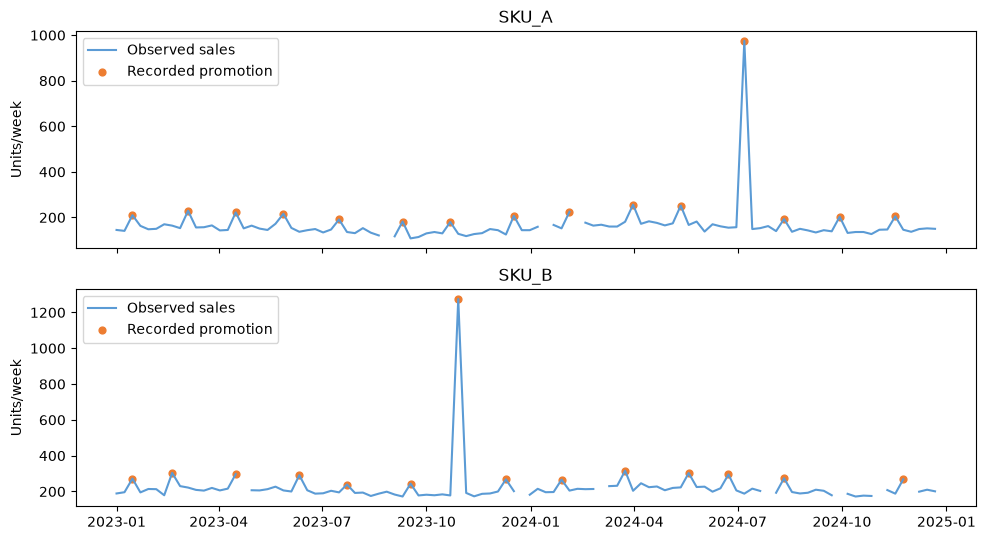

Gaps remain visible. Very high recorded promotion weeks are retained, not assumed erroneous.


In [14]:
raw_data = load_history()
history, audit, quarantined = review_history(raw_data)
display(history[['Week', 'SKU', 'Sales_Units', 'Is_Promo', 'Price']].head(3))
show_history(history, audit, quarantined)
plot_history(history)

**READ:** On 2023-01-01, SKU_A has 145 recorded sales units, no recorded promotion and a recorded unit price of 14.99. The next two weeks show 141 and 210 units; the third week has a promotion and price 9.99. The plot preserves gaps and unusually high recorded events.

**Forecast protocol:** the final 20 calendar weeks are the evaluation period. Forecasts are one week ahead and updated only after earlier actuals become available. Both windows and the naive method use the same eligible dates per SKU; a missing required week suppresses the prediction. Report the count of scored weeks. The stock example uses a dispersion estimate from weeks before this evaluation period.

**SD (standard deviation)** describes the spread of observed historical sales. The helper calculates it; interpret the resulting buffer rather than deriving a new formula.

**Stock rule:** SKU_A only; assume immediate replenishment before the next selling week and a one-week review/protection period. Inventory position is an illustrative input (no observed on-order/backlog data). Target = next-week 3-week forecast + factor × historical training sales SD. Order = round up max(0, target − position). This is not optimisation or a guaranteed service policy.

## 1. Verify the planning history

**BEFORE:** Read the raw/reviewed counts with details hidden.

**CHANGE:** SHOW_ISSUE_DETAILS: False → True. Reveal issue details. No data values change.

**AFTER:** Read the quarantined records and unknown sales weeks.

In [15]:
SHOW_ISSUE_DETAILS = False  # <-- CHANGE HERE: False -> True
show_history(history, audit, quarantined, show_details=SHOW_ISSUE_DETAILS)  # <-- OBSERVE OUTPUT

,Count
Raw export rows,206
Exact repeats removed,3
Invalid-date records quarantined,1
Conflicting records quarantined,2
Calendar SKU/weeks,208
Known sales weeks,198
Unknown sales weeks,10


,Calendar_weeks,Known_sales_weeks
SKU,,
SKU_A,104,101
SKU_B,104,97


Unknown sales are not zero. No promotion spikes or prices have been filled or capped.


**THINK**

1. Why are there more calendar rows than raw rows?

2. Why would treating every unknown week as zero change the business story?

3. Which unresolved records would you ask the data owner to clarify?

## 2. Compare promotion weeks

**BEFORE:** Read the overall observed mean for each SKU.

**CHANGE:** SHOW_PROMO_COMPARISON: False → True. Display separate promo and nonpromo means and counts.

**AFTER:** Inspect group sizes and observed percentage gaps.

In [16]:
SHOW_PROMO_COMPARISON = False  # <-- CHANGE HERE: False -> True
show_promotions(history, show_comparison=SHOW_PROMO_COMPARISON)  # <-- OBSERVE OUTPUT

,count,mean
SKU,,
SKU_A,101,165.46
SKU_B,97,222.79


These overall means do not separate promotion weeks.


**THINK**

1. How do the promotion-week means compare with nonpromotion weeks?

2. Does the difference prove that promotions caused extra demand?

3. What additional business information would help you assess the promotion?

## 3. Change the forecast window

**BEFORE:** Run the 3-week forecast and read its MAE, signed bias and scored counts.

**CHANGE:** WINDOW: 3 → 6. Use a 6-week window. The comparison dates remain fixed.

**AFTER:** Compare MAE and bias with the 3-week reference and naive benchmark.

,SKU,Method,Test calendar weeks,Scored weeks,Unscored weeks,MAE (units/week),Bias (forecast - actual)
0,SKU_A,Naive,20,20,0,23.20,-0.50
1,SKU_A,MA_3,20,20,0,20.67,-0.10
2,SKU_B,Naive,20,2,18,15.50,15.50
3,SKU_B,MA_3,20,2,18,15.00,8.33


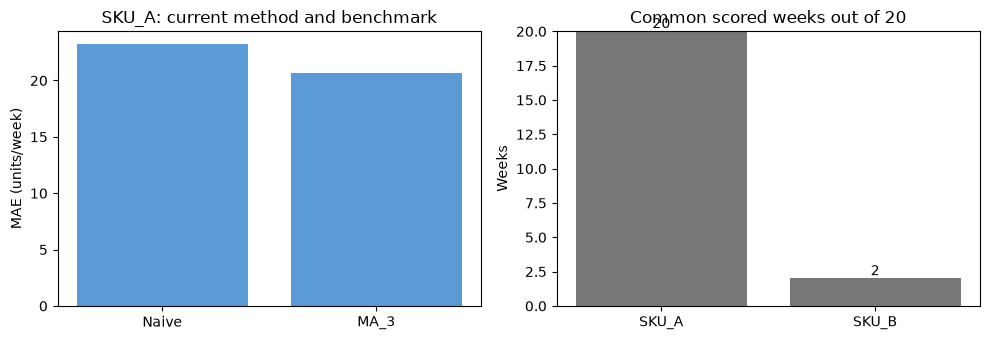

Compare the same dates. SKU_B has only two scored weeks; its method ranking is weak evidence.


,BEFORE MA_3 MAE,AFTER MA_3 MAE,MAE change (units/week)
SKU,,,
SKU_A,20.67,20.67,0.0
SKU_B,15.00,15.00,0.0


,Week,SKU,Sales_Units,Selected_forecast
16,2024-12-01,SKU_A,137.0,166.00
17,2024-12-08,SKU_A,149.0,162.67
18,2024-12-15,SKU_A,152.0,144.00
19,2024-12-22,SKU_A,150.0,146.00
20,2024-09-15,SKU_B,204.0,197.33
21,2024-09-22,SKU_B,179.0,202.33


Final 20 calendar weeks; the SAME complete-history dates are scored for both windows and the naive benchmark.
The displayed forecasts are one-week ahead, updated after each previous week closes. Positive bias means over-forecasting.
No test-based tuning is implied. Missing actuals/history are not replaced with zero.


In [17]:
WINDOW = 3  # <-- CHANGE HERE: 3 -> 6
metrics = compare_windows(history, window=WINDOW)  # <-- OBSERVE OUTPUT

**THINK**

1. Did the longer window improve MAE in this run?

2. What does the sign of bias mean here?

3. Why should we be cautious about the result for SKU_B?

## 4. Change inventory position

**BEFORE:** Reset to the SKU_A planning baseline: latest 3-week forecast, buffer factor 1.0, position 180 units.

**CHANGE:** INVENTORY_POSITION: 180 → 90. Set the illustrative inventory position to 90 units.

**AFTER:** Compare forecast, target stock and rounded order quantity.

,BEFORE,AFTER,CHANGE
Next-week forecast (units),150.33,150.33,0.0
Historical training sales SD (units/week),95.19,95.19,0.0
Buffer factor,1.00,1.00,0.0
Buffer stock (units),95.19,95.19,0.0
Target stock (units),245.52,245.52,0.0
Inventory position (units),180.00,180.00,0.0
"Order quantity, rounded up (units)",66.00,66.00,0.0


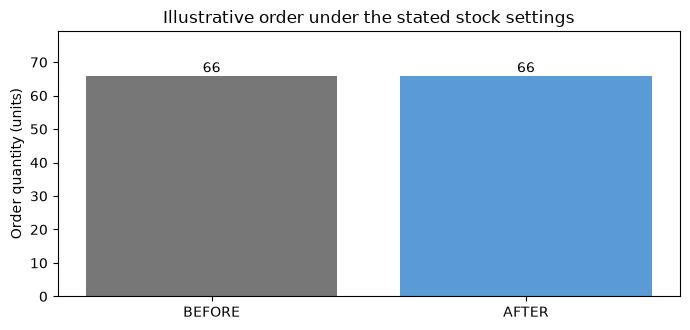

The forecast is fixed. Read inventory position and buffer settings before interpreting the different order.
SKU_A only; forecast is always the latest 3 observed weeks. Stock settings reset independently.
Illustrative one-week target: forecast + factor × historical training sales SD.
Assume immediate replenishment before the next selling week, weekly review, no backlog/on-order stock, no capacity or pack-size limits.
Inventory positions are teaching assumptions, not observations. Factor 1.65 does not guarantee 95% service.
Fractional forecast/buffer values are estimates; only the final order is rounded up to whole units.


In [18]:
INVENTORY_POSITION = 180  # <-- CHANGE HERE: 180 -> 90
plan = compare_stock(history, inventory_position=INVENTORY_POSITION, buffer_factor=1.0)  # <-- OBSERVE OUTPUT

**THINK**

1. Which values change when inventory position falls?

2. Why does the order change although the sales forecast stays the same?

3. Which real stock information would you verify before ordering?

## 5. Change the stock buffer

**BEFORE:** Reset inventory position to 180; retain the baseline SKU_A 3-week planning forecast. Run factor 1.0.

**CHANGE:** BUFFER_FACTOR: 1.0 → 1.65. Increase the factor to 1.65, with forecast, historical dispersion and position fixed.

**AFTER:** Compare buffer, target and rounded order quantity.

,BEFORE,AFTER,CHANGE
Next-week forecast (units),150.33,150.33,0.0
Historical training sales SD (units/week),95.19,95.19,0.0
Buffer factor,1.00,1.00,0.0
Buffer stock (units),95.19,95.19,0.0
Target stock (units),245.52,245.52,0.0
Inventory position (units),180.00,180.00,0.0
"Order quantity, rounded up (units)",66.00,66.00,0.0


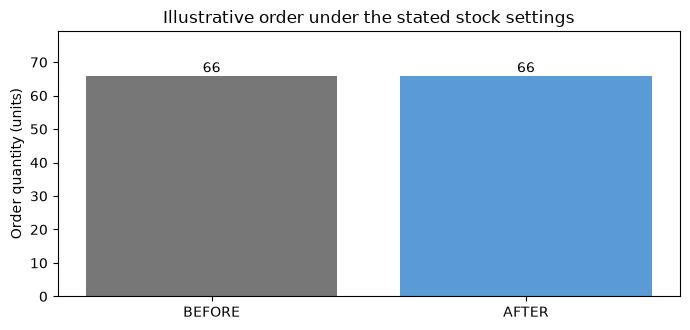

The forecast is fixed. Read inventory position and buffer settings before interpreting the different order.
SKU_A only; forecast is always the latest 3 observed weeks. Stock settings reset independently.
Illustrative one-week target: forecast + factor × historical training sales SD.
Assume immediate replenishment before the next selling week, weekly review, no backlog/on-order stock, no capacity or pack-size limits.
Inventory positions are teaching assumptions, not observations. Factor 1.65 does not guarantee 95% service.
Fractional forecast/buffer values are estimates; only the final order is rounded up to whole units.


In [19]:
BUFFER_FACTOR = 1.0  # <-- CHANGE HERE: 1.0 -> 1.65
plan = compare_stock(history, inventory_position=180, buffer_factor=BUFFER_FACTOR)  # <-- OBSERVE OUTPUT

**THINK**

1. How does the larger buffer affect the target and order?

2. Does this establish 95% service?

3. What trade-off should the planner discuss?

## Decision note
Write one finding, one limitation and one next action for the planner. Distinguish a forecast from an order and a policy assumption from an observed fact.